# Example: A Rule Switch in a Wolfram Market
In this example, we simulate the Wolfram market, an agent-based model in which traders on a grid act on the intentions of their four neighbors, and we change one entry of the rule that a fraction of the traders follow, to see whether the market turns toward selling.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Read a Wolfram rule as a policy:__ A Wolfram rule is a lookup table that maps the sum of the four neighbors' intentions to the trader's next intention. We print the tables of Rule 19280 and Rule 19286 and find the one neighbor sum at which they differ.
> * __Compare a switched market with its control:__ After a shared history, a fraction of the traders switch from Rule 19280 to Rule 19286. We plot the fraction of traders who intend to sell and the dealer's price for the switched market beside a control that never switches, under three market conditions.
> * __Measure how often a Sell majority forms:__ We count the fraction of random starting markets in which a Sell majority forms after the switch, and compare the largest fall in the price with the control. We then run a small switched market ourselves and change the conditions.

We follow the model in the [paper repository](https://github.com/varnerlab/Wolfram-markets-abm-paper); the cached results come from a larger grid than the one we run in class.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file
import VLQuantitativeFinancePackage.WolframMarkets as WM; # the rule-switch simulator, qualified so its names stay separate

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
The cached results in Tasks 2 and 3 come from the script `scripts/Compute-L12b-RuleSwitch-Cache.jl`, which runs many switched markets and their controls on a larger grid than we can run in class and saves them to `data/L12b-RuleSwitch-Cache.jld2`. The file holds three entries: `settings`, a `NamedTuple` that records how the cache was built; `pairs`, the full time series of a few switched markets and their controls; and `sweep`, a `DataFrame` with one row for each run. Let's load the file and print its settings, including the `provisional` flag, which is `true` only for a quick test cache:

In [2]:
cache = let

    # check that the cache file exists, and say how to build it if it does not -
    path = joinpath(_PATH_TO_DATA, "L12b-RuleSwitch-Cache.jld2");
    isfile(path) || error("Missing $(path). Build it with: julia -t auto scripts/Compute-L12b-RuleSwitch-Cache.jl");

    # load the three entries: settings, pairs, and sweep -
    d = load(path);
    s = d["settings"];

    # show the settings of the cache -
    df = DataFrame(
        setting = ["grid size (L)", "starting markets (seeds)", "fractions of switching traders (f)", "steps before the switch", "steps after the switch",
            "dealer depth and edge condition", "provisional"],
        value = [string(s.L), string(length(s.seeds)), join(s.f_values, ", "), string(s.t_pre), string(s.t_post),
            join(["h = $(c.h), :$(c.boundary_mode)" for c ∈ s.conditions], "; "), string(s.provisional)]
    );
    pretty_table(df; column_labels = ["setting", "value"], alignment = [:l, :l],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert haskey(d, "pairs") && haskey(d, "sweep") "the cache must hold settings, pairs, and sweep"
    @assert !isempty(d["pairs"]) && nrow(d["sweep"]) > 0 "the cache must not be empty"

    # return -
    d
end;

 ------------------------------------ ----------------------------------------------------------------
  setting                              value                                                          
 ------------------------------------ ----------------------------------------------------------------
  grid size (L)                        64
  starting markets (seeds)             20
  fractions of switching traders (f)   0.1, 0.14, 0.16, 0.18, 0.2, 0.25
  steps before the switch              1000
  steps after the switch               3000
  dealer depth and edge condition      h = 100.0, :hold; h = 100.0, :endogenous; h = 1.0, :endogenous
  provisional                          false
 ------------------------------------ ----------------------------------------------------------------


### Constants
Next, let's set the constants. The colors of the three intentions are the paper's: Buy is blue, Hold is gray, and Sell is orange. We reuse the orange for the switched market and a dark line for the control in every plot.

In [3]:
# the paper's colors for the three intentions -
color_buy = parse(Colorant, "#0072B2"); # Buy is blue
color_hold = parse(Colorant, "#AAAAAA"); # Hold is gray
color_sell = parse(Colorant, "#D55E00"); # Sell is orange

# line colors used in every plot -
color_switched = color_sell; # the switched market
color_control = colorant"black"; # the control market, which never switches
color_condition = Dict("h=100.0/hold" => parse(Colorant, "#009E73"), "h=100.0/endogenous" => parse(Colorant, "#CC79A7"),
    "h=1.0/endogenous" => colorant"black"); # one color for each market condition in Task 3

# the market conditions stored in the cache, and how we name them in the plots -
condition_names = Dict("h=100.0/hold" => "deep dealer, held edge", "h=100.0/endogenous" => "deep dealer, active edge",
    "h=1.0/endogenous" => "shallow dealer, active edge");
conditions = [string("h=", c.h, "/", c.boundary_mode) for c ∈ cache["settings"].conditions]; # condition labels, in cache order

___

## Task 1: Rules as Policies
In this task, we print the lookup tables of the baseline rule, Rule 19280, and the switch rule, Rule 19286, and find where they differ.

Every trader on the grid holds one of three intentions: Buy (coded 0), Hold (coded 1), or Sell (coded 2). At each step, a trader adds up the codes of its four neighbors, a neighbor sum between 0 (four Buy) and 8 (four Sell), and looks up its next intention in a table with one entry for each of the nine sums. That table is a policy: the neighbor sum is the state, and the intention is the action. A rule number writes the table in base 3, with the entry for neighbor sum 8 first and the entry for neighbor sum 0 last. [The rule_table(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) returns the nine entries in the opposite order, from neighbor sum 0 to 8, as the codes 0, 1, and 2.

Let's print both tables side by side, with a marker at any neighbor sum where they differ:

In [4]:
rule_tables = let

    # initialize: the two rule numbers and the names of the three intentions -
    baseline_rule = 19280; # the baseline rule, in base 3: 222110002
    switch_rule = 19286; # the switch rule, in base 3: 222110022
    intention_names = ["Buy", "Hold", "Sell"]; # codes 0, 1, 2

    # look up the nine entries of each rule: index k+1 holds the action for neighbor sum k -
    baseline = WM.rule_table(baseline_rule);
    switched = WM.rule_table(switch_rule);

    # build the table: one row for each neighbor sum -
    df = DataFrame(
        neighbor_sum = 0:8,
        baseline = intention_names[baseline .+ 1],
        switched = intention_names[switched .+ 1],
        differs = [baseline[k] != switched[k] ? "<-- differs" : "" for k ∈ 1:9]
    );
    println("Rule $(baseline_rule) in base 3: ", string(baseline_rule, base = 3), "; Rule $(switch_rule) in base 3: ", string(switch_rule, base = 3));
    pretty_table(df; column_labels = ["neighbor sum", "Rule $(baseline_rule)", "Rule $(switch_rule)", ""],
        alignment = [:r, :l, :l, :l], table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert length(baseline) == 9 && length(switched) == 9 "each rule has nine entries"
    @assert count(baseline .!= switched) == 1 "the two rules must differ in exactly one entry"
    @assert baseline[2] == 0 && switched[2] == 2 "at neighbor sum 1, the baseline buys and the switch rule sells"

    # return -
    (baseline = baseline, switched = switched)
end;

Rule 19280 in base 3: 222110002; Rule 19286 in base 3: 222110022
 -------------- ------------ ------------ -------------
  neighbor sum   Rule 19280   Rule 19286               
 -------------- ------------ ------------ -------------
             0   Sell         Sell
             1   Buy          Sell         <-- differs
             2   Buy          Buy
             3   Buy          Buy
             4   Hold         Hold
             5   Hold         Hold
             6   Sell         Sell
             7   Sell         Sell
             8   Sell         Sell
 -------------- ------------ ------------ -------------


> __What do we see?__
>
> * __One entry differs:__ The two tables agree at every neighbor sum except 1, which the last column marks. At neighbor sum 1, which is three Buy neighbors and one Hold neighbor, Rule 19280 gives Buy and Rule 19286 gives Sell.
> * __Everything else is the same:__ Both rules give Sell at neighbor sum 0 and at neighbor sums 6 to 8, and Hold at neighbor sums 4 and 5. A switching trader changes its action in one kind of neighborhood only.

___

## Task 2: A Switched Market and Its Control (Cached)
In this task, we plot cached switched markets beside their controls, for a small and a large fraction $f$ of traders who switch to Rule 19286.

In each market, all interior traders follow Rule 19280 for the first stretch of steps. At the switch step, a fraction $f$ of the interior traders change to Rule 19286. A dealer sets the price: net buying from the dealer raises it and net selling lowers it, and the dealer's depth $h$ controls how far a given net order moves the price. Traders on the edge of the grid are technical traders. In the __held__ condition they keep their intention and the price has no feedback on them; in the __active__ condition they read the dealer's price and trade against its recent moves.

The control market shares the history of the switched market up to the switch step and never switches, so any difference after the switch is due to the rule change. We also include a market with a shallow dealer, because a shallow dealer can move the price a long way with no switch at all.

`Unhide` the code cell below to see the plotting function that we use in Tasks 2 and 4. It draws the fraction of interior traders who intend to sell, and the dealer's price, for a switched market and its control on the same axes, with a vertical line at the switch step.

In [5]:
# plot_pair: Sell fraction (top) and dealer price (bottom) for one switched market and its control -
function plot_pair(switched, control, t_pre::Int; title_text::String = "", price_limits = nothing, show_legend::Bool = false)

    # time axes: one point for each recorded step, starting at step 0 -
    t_sell = 0:(length(switched.sell_fraction) - 1);
    t_price = 0:(length(switched.prices) - 1);

    # top panel: fraction of interior traders who intend to sell -
    p_sell = plot(t_sell, control.sell_fraction, label = show_legend ? "control" : "", color = color_control, linewidth = 1.5,
        title = title_text, ylabel = "Sell fraction", ylims = (0.0, 1.0), legend = show_legend ? :topleft : false,
        bg = "gray95", background_color_outside = "white", framestyle = :box, xticks = 0:1000:4000);
    plot!(p_sell, t_sell, switched.sell_fraction, label = show_legend ? "switched" : "", color = color_switched, linewidth = 1.5);
    hline!(p_sell, [0.5], label = "", color = :gray, linestyle = :dot); # a Sell majority is above this line
    vline!(p_sell, [t_pre], label = show_legend ? "switch step" : "", color = :gray, linestyle = :dash);

    # bottom panel: the dealer's price; both panels in a figure share the same price limits -
    p_price = plot(t_price, control.prices, label = "", color = color_control, linewidth = 1.5, xlabel = "step", ylabel = "dealer price (log scale)",
        yscale = :log10, yformatter = y -> string(round(Int, y)), ylims = isnothing(price_limits) ? :auto : price_limits, legend = false,
        bg = "gray95", background_color_outside = "white", framestyle = :box, xticks = 0:1000:4000);
    plot!(p_price, t_price, switched.prices, label = "", color = color_switched, linewidth = 1.5);
    vline!(p_price, [t_pre], label = "", color = :gray, linestyle = :dash);

    # return -
    (p_sell, p_price)
end;

# pair_for: the cached pair for one condition and one fraction f -
pair_for(condition::String, f::Float64) = first(filter(p -> string("h=", p.h, "/", p.boundary_mode) == condition && p.f == f, cache["pairs"]));

# headline fractions: the smallest and the largest f in the cached pairs -
headline_f = sort(unique([p.f for p ∈ cache["pairs"]]));

Before we plot, let's list the numbers behind the plots. The table shows, for each cached pair, whether the switched market reached a Sell majority, the number of steps after the switch until it did, the mean Sell fraction over the last 500 steps, and the __drawdown__, the largest fall in the dealer's price from a running peak after the switch (0.25 is a fall of 25%), for the switched market and for its control:

In [6]:
let

    # initialize: the sweep rows for the headline pairs (the pairs use the first seed) -
    sw = cache["sweep"];
    rows = [first(filter(r -> r.condition == c && r.f == f && r.seed == 1, sw)) for c ∈ conditions for f ∈ headline_f];

    # build the table: one row for each cached pair -
    df = DataFrame(
        condition = [condition_names[r.condition] for r ∈ rows],
        f = [r.f for r ∈ rows],
        sell_majority = [r.transitioned ? "yes" : "no" for r ∈ rows],
        onset = [r.onset for r ∈ rows],
        final_sell = [r.final_sell_mean for r ∈ rows],
        drawdown = [r.max_drawdown for r ∈ rows],
        control_drawdown = [r.control_max_drawdown for r ∈ rows]
    );
    pretty_table(df; column_labels = ["condition", "f", "Sell majority", "steps to majority", "final Sell fraction", "drawdown", "control drawdown"],
        alignment = [:l, :r, :c, :r, :r, :r, :r], formatters = [fmt__printf("%.2f", [2]), fmt__printf("%.3f", [5, 6, 7])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: the table must agree with the stored time series (mean of the last 500 steps) -
    for r ∈ rows
        p = pair_for(r.condition, r.f);
        @assert isapprox(mean(p.switched.sell_fraction[(end - 499):end]), r.final_sell_mean; atol = 1e-12) "table and time series must agree"
    end
end

 ----------------------------- ------ --------------- ------------------- --------------------- ---------- ------------------
  condition                        f   Sell majority   steps to majority   final Sell fraction   drawdown   control drawdown 
 ----------------------------- ------ --------------- ------------------- --------------------- ---------- ------------------
  deep dealer, held edge        0.10        no                         0                 0.256      0.032              0.014
  deep dealer, held edge        0.25        yes                      333                 0.863      0.257              0.014
  deep dealer, active edge      0.10        no                         0                 0.258      0.029              0.008
  deep dealer, active edge      0.25        yes                      245                 0.878      0.256              0.008
  shallow dealer, active edge   0.10        no                         0                 0.259      0.454              0.3

Let's start with the held condition and a deep dealer. The top row of the figure shows the Sell fraction and the bottom row shows the price, with the smaller $f$ on the left and the larger $f$ on the right:

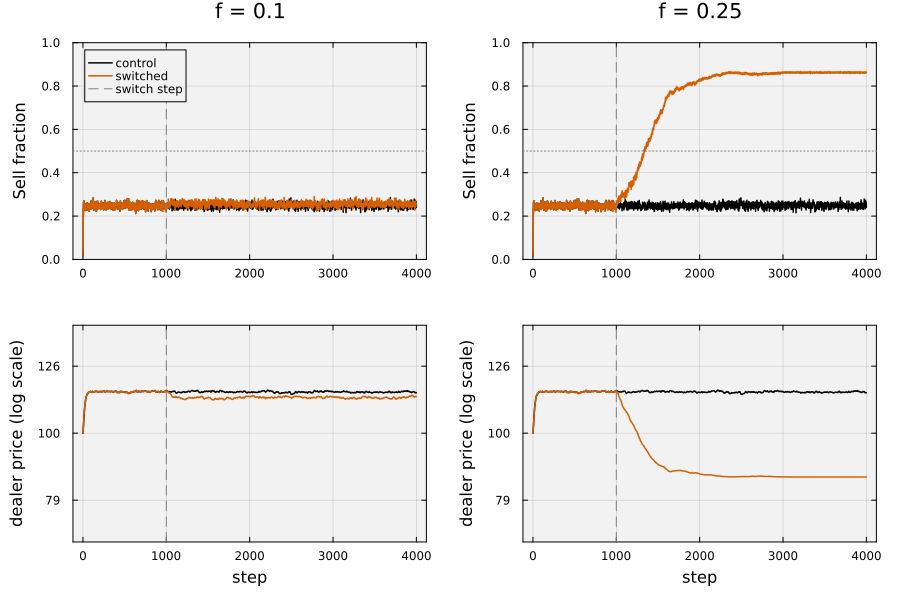

In [7]:
let

    # initialize: the condition, and the price limits shared by all four panels -
    condition = "h=100.0/hold";
    pairs_here = [pair_for(condition, f) for f ∈ headline_f];
    all_prices = vcat([vcat(p.switched.prices, p.control.prices) for p ∈ pairs_here]...);
    price_limits = (0.8 * minimum(all_prices), 1.25 * maximum(all_prices));

    # draw one column for each f: Sell fraction on top, price below -
    panels = [plot_pair(p.switched, p.control, p.t_pre; title_text = "f = $(p.f)", price_limits = price_limits, show_legend = (i == 1)) for (i, p) ∈ enumerate(pairs_here)];
    plt = plot(panels[1][1], panels[2][1], panels[1][2], panels[2][2], layout = (2, 2), size = (900, 600), margin = 4Plots.mm);

    # checks -
    @assert all(p.switched.sell_fraction[1:p.t_pre] == p.control.sell_fraction[1:p.t_pre] for p ∈ pairs_here) "switched and control must share their history"

    # return -
    plt
end

> __What do we see?__
>
> * __f = 0.1:__ The Sell fractions of the switched market and the control overlap after the switch and stay below the dotted majority line. The switched price sits a little below the control price, and the table gives a drawdown of 0.032 against 0.014 for the control.
> * __f = 0.25:__ The Sell fraction of the switched market rises above the dotted line 333 steps after the switch and levels off at 0.863, while the control stays flat. The switched price falls and levels off, with a drawdown of 0.257 against 0.014 for the control.

Next, the active condition with the same deep dealer, where the edge traders react to the price:

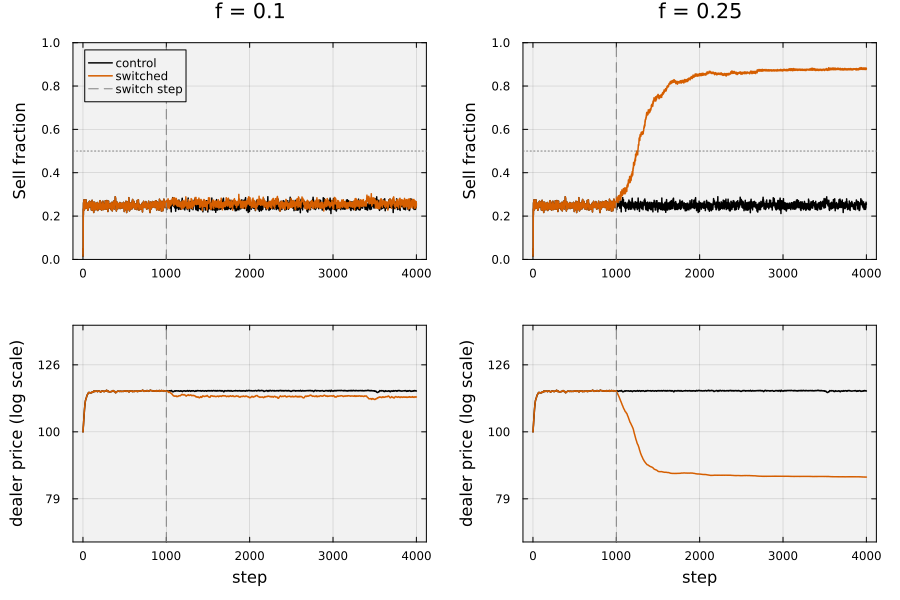

In [8]:
let

    # initialize: the condition, and the price limits shared by all four panels -
    condition = "h=100.0/endogenous";
    pairs_here = [pair_for(condition, f) for f ∈ headline_f];
    all_prices = vcat([vcat(p.switched.prices, p.control.prices) for p ∈ pairs_here]...);
    price_limits = (0.8 * minimum(all_prices), 1.25 * maximum(all_prices));

    # draw one column for each f: Sell fraction on top, price below -
    panels = [plot_pair(p.switched, p.control, p.t_pre; title_text = "f = $(p.f)", price_limits = price_limits, show_legend = (i == 1)) for (i, p) ∈ enumerate(pairs_here)];
    plt = plot(panels[1][1], panels[2][1], panels[1][2], panels[2][2], layout = (2, 2), size = (900, 600), margin = 4Plots.mm);

    # checks -
    @assert all(p.switched.sell_fraction[1:p.t_pre] == p.control.sell_fraction[1:p.t_pre] for p ∈ pairs_here) "switched and control must share their history"

    # return -
    plt
end

> __What do we see?__
>
> * __f = 0.1:__ As in the held condition, the Sell fractions overlap after the switch and stay below the dotted line, and the switched price sits slightly below the control price. The drawdown is 0.029 against 0.008 for the control.
> * __f = 0.25:__ The Sell fraction of the switched market crosses the dotted line 245 steps after the switch and levels off at 0.878, and its price falls with a drawdown of 0.256 against 0.008 for the control. In this pair, the Sell majority forms earlier than in the held condition.

Finally, the active condition with a shallow dealer. Look at the control as well as the switched market:

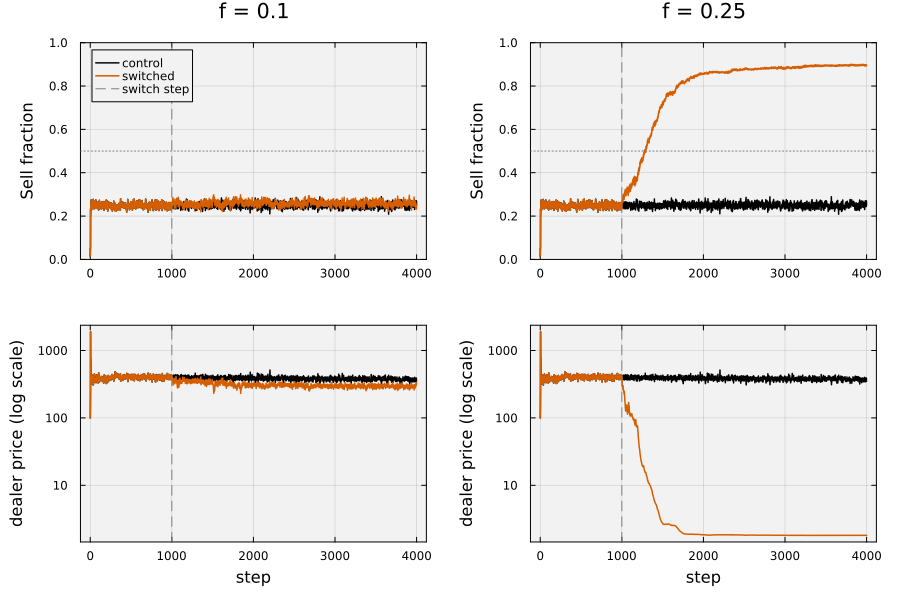

In [9]:
let

    # initialize: the condition, and the price limits shared by all four panels -
    condition = "h=1.0/endogenous";
    pairs_here = [pair_for(condition, f) for f ∈ headline_f];
    all_prices = vcat([vcat(p.switched.prices, p.control.prices) for p ∈ pairs_here]...);
    price_limits = (0.8 * minimum(all_prices), 1.25 * maximum(all_prices));

    # draw one column for each f: Sell fraction on top, price below -
    panels = [plot_pair(p.switched, p.control, p.t_pre; title_text = "f = $(p.f)", price_limits = price_limits, show_legend = (i == 1)) for (i, p) ∈ enumerate(pairs_here)];
    plt = plot(panels[1][1], panels[2][1], panels[1][2], panels[2][2], layout = (2, 2), size = (900, 600), margin = 4Plots.mm);

    # checks -
    @assert all(p.switched.sell_fraction[1:p.t_pre] == p.control.sell_fraction[1:p.t_pre] for p ∈ pairs_here) "switched and control must share their history"

    # return -
    plt
end

> __What do we see?__
>
> * __f = 0.1:__ Neither Sell fraction reaches the dotted line, but both prices swing widely. The drawdown of the switched market, 0.454, is only a little above the 0.397 of the control, so this fall cannot be assigned to the switch.
> * __f = 0.25:__ The Sell fraction crosses the dotted line 277 steps after the switch and the price falls by almost all of its value, a drawdown of 0.996. The control's price also falls 0.397 from a running peak with no switch, which is why we read the two together.

The plots show only the fraction of traders who intend to sell. Let's also look at the grids themselves at the last step, for the larger $f$. Buy is blue, Hold is gray, and Sell is orange, as in the paper:

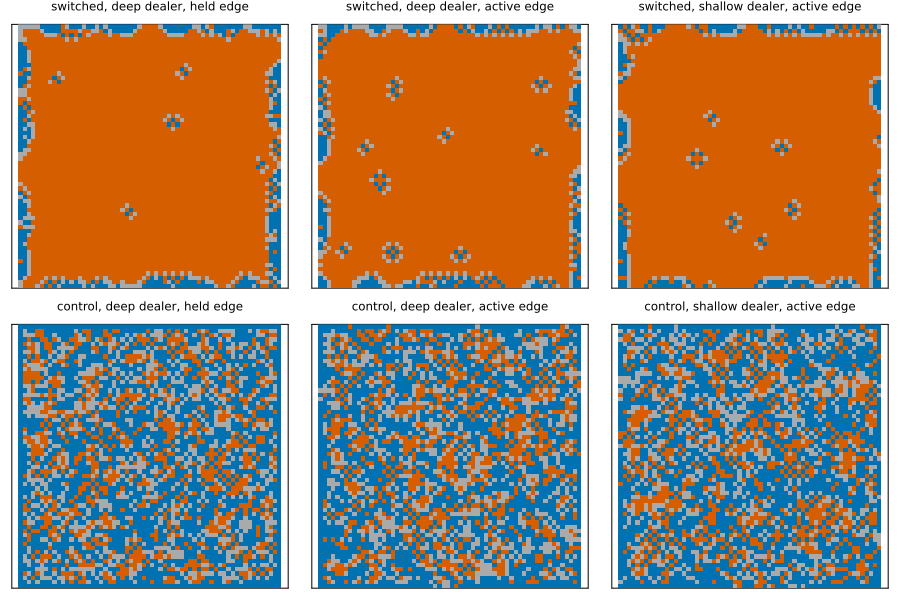

In [10]:
let

    # initialize: the color map for the codes 0, 1, 2 (Buy, Hold, Sell) and the larger fraction -
    cmap = cgrad([color_buy, color_hold, color_sell], 3, categorical = true);
    f_large = maximum(headline_f);

    # draw the interior traders at the last step: switched market on top, control below -
    panels = Plots.Plot[];
    for arm ∈ (:switched, :control), c ∈ conditions
        p = pair_for(c, f_large);
        frame = getfield(p, arm).frames.final[2:(end - 1), 2:(end - 1)]; # interior traders only
        push!(panels, heatmap(frame, color = cmap, clims = (-0.5, 2.5), colorbar = false, aspect_ratio = :equal, framestyle = :box,
            xticks = false, yticks = false, title = "$(arm == :switched ? "switched" : "control"), $(condition_names[c])", titlefontsize = 8,
            background_color_outside = "white"));
    end
    plt = plot(panels..., layout = (2, 3), size = (900, 600));

    # return -
    plt
end

> __What do we see?__
>
> * __Switched markets (top row):__ In all three conditions, Sell fills most of the grid. Narrow bands of Buy and Hold remain along parts of the border, and a few small clusters remain inside.
> * __Controls (bottom row):__ In all three conditions, the three intentions are mixed across the grid and no large region of Sell forms.

___

## Task 3: How Often Does a Sell Majority Form? (Cached)
In this task, we count how often a Sell majority forms across many starting markets, for each fraction $f$ and each market condition.

A single market can mislead, so the cached sweep ran many starting markets (seeds) for every fraction $f$ and condition. We say a market has a __Sell majority__ if the Sell fraction reaches one half at some step after the switch. For each $f$ and condition, we compute the fraction of starting markets with a Sell majority, and the median drawdown of the switched markets and of their controls. Because the control never switches, its numbers do not depend on $f$.

Let's start with the fraction of starting markets that form a Sell majority, for the switched markets and for their controls:

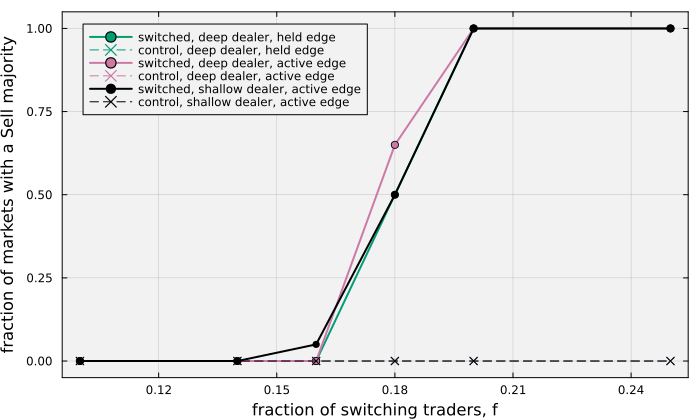

In [11]:
summary_df = let

    # initialize: group the sweep by condition and fraction f -
    sw = cache["sweep"];
    df = combine(groupby(sw, [:condition, :f]),
        :transitioned => mean => :fraction_majority,
        :control_transitioned => mean => :control_fraction_majority,
        :max_drawdown => median => :median_drawdown,
        :control_max_drawdown => median => :median_control_drawdown,
        nrow => :number_of_markets);
    sort!(df, [order(:condition, by = c -> findfirst(==(c), conditions)), :f]); # fix the row order (cache order); groupby order is not defined

    # draw: one line for each condition, solid for the switched markets and dashed for the controls -
    f_values = sort(unique(df.f));
    plt = plot(xlabel = "fraction of switching traders, f", ylabel = "fraction of markets with a Sell majority", ylims = (-0.05, 1.05),
        bg = "gray95", background_color_outside = "white", framestyle = :box, legend = :topleft, size = (700, 420));
    for c ∈ conditions
        d = filter(r -> r.condition == c, df);
        plot!(plt, d.f, d.fraction_majority, label = "switched, " * condition_names[c], color = color_condition[c], marker = :circle, linewidth = 2);
        plot!(plt, d.f, d.control_fraction_majority, label = "control, " * condition_names[c], color = color_condition[c], marker = :x, linestyle = :dash, linewidth = 1);
    end
    display(plt);

    # checks -
    @assert all(df.number_of_markets .== length(cache["settings"].seeds)) "every f and condition uses every starting market"
    @assert all(0.0 .<= df.fraction_majority .<= 1.0) "fractions must lie in [0, 1]"

    # return -
    df
end;

> __What do we see?__
>
> * __Switched markets:__ In each condition, the fraction of starting markets with a Sell majority is zero at the smallest fractions, rises as f increases, and reaches one at the largest fractions. The three solid curves stay close to each other.
> * __Controls:__ The dashed lines stay at zero for every f and every condition, so no control forms a Sell majority.

Now let's put the numbers in a table. For each condition and $f$, the table lists the fraction of starting markets with a Sell majority, and the median drawdown of the switched markets and of their controls side by side:

In [12]:
let

    # build the table: one row for each condition and fraction f -
    df = DataFrame(
        condition = [condition_names[c] for c ∈ summary_df.condition],
        f = summary_df.f,
        majority = summary_df.fraction_majority,
        control_majority = summary_df.control_fraction_majority,
        drawdown = summary_df.median_drawdown,
        control_drawdown = summary_df.median_control_drawdown
    );
    pretty_table(df; column_labels = ["condition", "f", "switched: Sell majority", "control: Sell majority", "switched: median drawdown", "control: median drawdown"],
        alignment = [:l, :r, :r, :r, :r, :r], formatters = [fmt__printf("%.2f", [2, 3, 4]), fmt__printf("%.3f", [5, 6])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: the switched and the control columns must both be present -
    @assert all(c ∈ names(df) for c ∈ ["drawdown", "control_drawdown", "majority", "control_majority"]) "table needs switched and control columns"
end

 ----------------------------- ------ ------------------------- ------------------------ --------------------------- --------------------------
  condition                        f   switched: Sell majority   control: Sell majority   switched: median drawdown   control: median drawdown 
 ----------------------------- ------ ------------------------- ------------------------ --------------------------- --------------------------
  deep dealer, held edge        0.10                      0.00                     0.00                       0.030                      0.012
  deep dealer, held edge        0.14                      0.00                     0.00                       0.047                      0.012
  deep dealer, held edge        0.16                      0.00                     0.00                       0.065                      0.012
  deep dealer, held edge        0.18                      0.50                     0.00                       0.180                      0.

> __What do we see?__
>
> * __Switched markets:__ In every condition, the median drawdown does not fall as f increases, and it is larger than the control's at every f. With a deep dealer, it reaches 0.255 and 0.258 at the largest f, against 0.012 and 0.008 for the controls.
> * __Shallow dealer:__ The control's median drawdown is 0.333, far above 0.008 and 0.012 for the deep dealer. At f = 0.10, the switched median of 0.400 is only a little above it.

___

## Task 4: Try It Yourself (Live, Small Grid)
In this task, we run a switched market and its control ourselves, on a grid much smaller than the cached one.

The next cell sets the parameters. The edge condition `boundary_mode` has three choices: `:endogenous` (active edge traders who read the dealer's price), `:hold` (held edge traders), and `:random` (a course addition, not a result from the paper: each edge trader draws Buy, Hold, or Sell with fixed probabilities at every step, so the edge has no price feedback and no memory). The cell also sets the probabilities of the random draws, which `:random` uses and the other two conditions ignore. The defaults use a fraction $f$ for which the cached results show a Sell majority in most starting markets. The grid is smaller than the cached one, so results can differ from Tasks 2 and 3. Change the parameters and run the cells again:

In [13]:
# the live market -
L = 32; # grid size (L × L traders, including the edge); the cached grid is larger
f = 0.25; # fraction of interior traders that switch to Rule 19286
h = 100.0; # dealer depth; a small value (for example 1.0) makes the price move a long way for a given net order
boundary_mode = :endogenous; # edge traders: :endogenous (active), :hold (held), or :random (random draws)
seed = 1; # starting market; each seed gives a different random start
random_probabilities = (1/3, 1/3, 1/3); # probabilities of (Buy, Hold, Sell) for :random edge traders; ignored otherwise
t_pre = 1000; # steps before the switch (the same as in the cache)
t_post = 3000; # steps after the switch (the same as in the cache)

Let's run the switched market and its control. [The run_rule_switch(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) runs both with the same history up to the switch, and [the rule_switch_summary(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) computes the same summary numbers as the cached sweep. We time the run and print the summary:

In [14]:
live = let

    # initialize: the run keywords; the random-edge probabilities only matter for :random -
    kw = boundary_mode == :random ? (random_edge_probabilities = random_probabilities,) : NamedTuple();

    # run the switched market and its control, and time it -
    t_run = @elapsed pair = WM.run_rule_switch(; L = L, f = f, h = h, seed = seed, boundary_mode = boundary_mode, t_pre = t_pre, t_post = t_post, kw...);
    s = WM.rule_switch_summary(pair);

    # show the summary: one row for the switched market and one for the control -
    df = DataFrame(
        market = ["switched", "control"],
        sell_majority = [s.transitioned ? "yes" : "no", s.control_transitioned ? "yes" : "no"],
        onset = [s.onset, 0],
        final_sell = [s.final_sell_mean, s.control_final_sell_mean],
        drawdown = [s.max_drawdown, s.control_max_drawdown]
    );
    println("run time: $(round(t_run; digits = 1)) seconds");
    pretty_table(df; column_labels = ["market", "Sell majority", "steps to majority", "final Sell fraction", "drawdown"],
        alignment = [:l, :c, :r, :r, :r], formatters = [fmt__printf("%.3f", [4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert pair.switched.sell_fraction[1:t_pre] == pair.control.sell_fraction[1:t_pre] "switched and control must share their history"
    @assert length(pair.switched.prices) == t_pre + t_post + 1 "one price for each step, including step 0"

    # return -
    (pair = pair, summary = s)
end;

run time: 1.9 seconds
 ---------- --------------- ------------------- --------------------- ----------
  market     Sell majority   steps to majority   final Sell fraction   drawdown 
 ---------- --------------- ------------------- --------------------- ----------
  switched        yes                      681                 0.783      0.237
  control         no                         0                 0.236      0.013
 ---------- --------------- ------------------- --------------------- ----------


Let's plot the live market in the same way as in Task 2, with the switched market and the control on the same axes and a vertical line at the switch step:

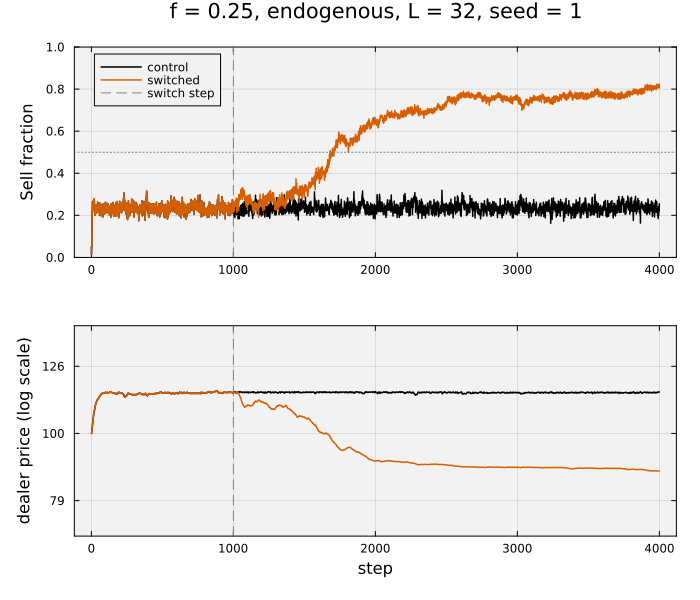

In [15]:
let

    # draw: Sell fraction on top, dealer price below, as in Task 2 -
    p = live.pair;
    prices = vcat(p.switched.prices, p.control.prices);
    (p_sell, p_price) = plot_pair(p.switched, p.control, p.t_pre; title_text = "f = $(f), $(boundary_mode), L = $(L), seed = $(seed)",
        price_limits = (0.8 * minimum(prices), 1.25 * maximum(prices)), show_legend = true);
    plt = plot(p_sell, p_price, layout = (2, 1), size = (700, 600), margin = 4Plots.mm);

    # return -
    plt
end

> __What do we see?__
>
> * __Sell fraction:__ The switched market crosses the dotted line 681 steps after the switch, later than the cached pair at the same f, which crossed after 245 steps. It is still rising at the last step, and its final Sell fraction of 0.783 is below the 0.878 of the cached pair.
> * __Price:__ The switched price falls slowly after the switch, a drawdown of 0.237 against 0.013 for the control, whose price stays flat.

The edge condition is the parameter that changes the live market most easily. Let's run all three edge conditions with the same $f$, $h$, and seed, and compare their summaries:

In [16]:
let

    # initialize: the three edge conditions, and the timer -
    modes = [:endogenous, :hold, :random];
    rows = NamedTuple[];
    t_total = @elapsed for m ∈ modes

        # run the switched market and its control for this edge condition -
        kw = m == :random ? (random_edge_probabilities = random_probabilities,) : NamedTuple();
        pair = WM.run_rule_switch(; L = L, f = f, h = h, seed = seed, boundary_mode = m, t_pre = t_pre, t_post = t_post, kw...);
        s = WM.rule_switch_summary(pair);
        push!(rows, (mode = string(m), majority = s.transitioned ? "yes" : "no", onset = s.onset, final_sell = s.final_sell_mean,
            drawdown = s.max_drawdown, control_drawdown = s.control_max_drawdown));
    end

    # show the table -
    println("run time for the three edge conditions: $(round(t_total; digits = 1)) seconds");
    pretty_table(DataFrame(rows); column_labels = ["edge condition", "Sell majority", "steps to majority", "final Sell fraction", "drawdown", "control drawdown"],
        alignment = [:l, :c, :r, :r, :r, :r], formatters = [fmt__printf("%.3f", [4, 5, 6])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert length(rows) == 3 "one row for each edge condition"
end

run time for the three edge conditions: 0.8 seconds
 ---------------- --------------- ------------------- --------------------- ---------- ------------------
  edge condition   Sell majority   steps to majority   final Sell fraction   drawdown   control drawdown 
 ---------------- --------------- ------------------- --------------------- ---------- ------------------
  endogenous            yes                      681                 0.783      0.237              0.013
  hold                  yes                     1137                 0.697      0.216              0.023
  random                yes                      326                 0.854      0.255              0.023
 ---------------- --------------- ------------------- --------------------- ---------- ------------------


A single seed is one starting market. Let's repeat the run of the parameter cell for five seeds, with the `boundary_mode` that we set above:

In [17]:
let

    # initialize: five starting markets, and the timer -
    seeds = 1:5;
    rows = NamedTuple[];
    t_total = @elapsed for sd ∈ seeds

        # run the switched market and its control for this seed -
        kw = boundary_mode == :random ? (random_edge_probabilities = random_probabilities,) : NamedTuple();
        pair = WM.run_rule_switch(; L = L, f = f, h = h, seed = sd, boundary_mode = boundary_mode, t_pre = t_pre, t_post = t_post, kw...);
        s = WM.rule_switch_summary(pair);
        push!(rows, (seed = sd, majority = s.transitioned ? "yes" : "no", onset = s.onset, final_sell = s.final_sell_mean,
            drawdown = s.max_drawdown, control_drawdown = s.control_max_drawdown));
    end

    # show the table -
    println("run time for five seeds: $(round(t_total; digits = 1)) seconds");
    pretty_table(DataFrame(rows); column_labels = ["seed", "Sell majority", "steps to majority", "final Sell fraction", "drawdown", "control drawdown"],
        alignment = [:r, :c, :r, :r, :r, :r], formatters = [fmt__printf("%.3f", [4, 5, 6])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks -
    @assert length(rows) == length(seeds) "one row for each seed"
end

run time for five seeds: 0.8 seconds
 ------ --------------- ------------------- --------------------- ---------- ------------------
  seed   Sell majority   steps to majority   final Sell fraction   drawdown   control drawdown 
 ------ --------------- ------------------- --------------------- ---------- ------------------
     1        yes                      681                 0.783      0.237              0.013
     2        yes                      443                 0.820      0.239              0.013
     3        yes                      668                 0.799      0.237              0.009
     4        yes                      743                 0.771      0.244              0.008
     5        yes                     2624                 0.495      0.206              0.008
 ------ --------------- ------------------- --------------------- ---------- ------------------


> __What do we see?__
>
> * __Edge conditions:__ All three edge conditions give a Sell majority, after 326 to 1,137 steps, and each switched drawdown, from 0.216 to 0.255, is far above its control drawdown of 0.013 or 0.023.
> * __Seeds:__ All five seeds form a Sell majority, but the number of steps ranges from 443 to 2,624. For seed 5, the final Sell fraction, 0.495, is below one half, so a majority can form and then fade.

___

## Summary
In this example, we compared two Wolfram rules as policies, simulated a switch from one to the other in a market with a dealer and a control, counted how often a Sell majority forms, and ran a small switched market ourselves.

> __Key Takeaways:__
>
> * __A rule switch changes one entry of a policy:__ We printed the lookup tables of Rule 19280 and Rule 19286 and found that they differ at a single neighbor sum, the one with three Buy neighbors and one Hold neighbor. Because each trader looks up its next intention from this table, giving a fraction of the traders the second rule changes what they do in exactly one neighborhood and nowhere else.
> * __The control isolates the effect of the switch:__ We plotted the Sell fraction and the dealer's price for a switched market beside a control that shares its history and never switches, with held and active edge traders and with a deep and a shallow dealer. This let us attribute the changes after the switch to the rule change, and showed that a shallow dealer can move the price a long way even without one.
> * __How often a Sell majority forms depends on the fraction who switch:__ We repeated the switch for many starting markets and several fractions, and counted the markets with a Sell majority and compared the fall in the price with the control. This showed that a larger fraction of switching traders makes a Sell majority more likely, and that a live run on a smaller grid can differ from the cached results.

We can now change the grid size, the fraction of switching traders, the dealer's depth, the edge condition, and the starting market, and see how the Sell fraction and the price respond.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___